# 04 · B2: a quina edat falla la bateria, comparat amb el reglament

El reglament (UE) 2023/1670 exigeix, des del 20 de juny de 2025, que la bateria d'un smartphone conservi el **80 % de la capacitat després de 800 cicles** complets. El reglament compta cicles, no anys: els convertim amb tres **escenaris d'ús** (0,5, 0,75 i 1 cicle complet al dia). Són supòsits, no mesures.

- **Resultat principal:** només MobiFix (tipus d'avaria posat per persones).
- **Complement no validat:** el conjunt amb el tipus d'avaria del classificador (quadern 02), que afegeix més casos i els anys 2021–2026.

L'edat és la del dia de la reparació, i només dels mòbils que arriben a un Repair Café.

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import comu

rng = np.random.default_rng(42)
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
BATERIA, PANTALLA, GRIS = "#eb6834", "#2a78d6", "#8f8e89"

dades = comu.carrega_classificats()
mf = dades[(dades["font_avaria"] == "MobiFix") & dades["edat_neta"].notna()]
bat_mf, pan_mf = mf[mf["grup_avaria"] == "Bateria i alimentació"], mf[mf["grup_avaria"] == "Pantalla"]
tots = dades[dades["edat_neta"].notna()]
bat_tots = tots[tots["grup_avaria"] == "Bateria i alimentació"]
print(f"MobiFix amb edat: bateria {len(bat_mf)}, pantalla {len(pan_mf)}  ·  conjunt classificat: bateria {len(bat_tots)}")

MobiFix amb edat: bateria 52, pantalla 160  ·  conjunt classificat: bateria 213


In [2]:
def mediana_ic(df, columna="edat_neta", n_boot=1000):
    """Mediana i IC 95 % per bootstrap agrupat per grup de reparació."""
    valors = list(df.groupby("group_identifier")[columna].apply(np.asarray).values)
    boots = [np.median(np.concatenate([valors[i] for i in rng.integers(0, len(valors), len(valors))]))
             for _ in range(n_boot)]
    return pd.Series({"n": len(df), "mediana": df[columna].median(),
                      "ic_inf": np.percentile(boots, 2.5), "ic_sup": np.percentile(boots, 97.5)})

## Resultat principal (MobiFix)

In [3]:
pd.concat({"Bateria": mediana_ic(bat_mf), "Pantalla (referència)": mediana_ic(pan_mf)}, axis=1).T

,n,mediana,ic_inf,ic_sup
Bateria,52.0,4.0,3.5,5.0
Pantalla (referència),160.0,2.5,2.0,3.0


In [4]:
ESCENARIS = [0.5, 0.75, 1.0]

def per_sobre(df, cicles=800):
    return pd.Series({f"{e} cicles/dia ({cicles / (e * 365):.1f} anys)": (df["edat_neta"] > cicles / (e * 365)).mean()
                      for e in ESCENARIS})

anys = pd.DataFrame({f"{c} cicles": {f"{e} cicles/dia": c / (e * 365) for e in ESCENARIS} for c in (800, 1000)})
display(anys.round(1))
pd.DataFrame({"MobiFix": per_sobre(bat_mf), "Conjunt classificat": per_sobre(bat_tots)}).round(2)

,800 cicles,1000 cicles
0.5 cicles/dia,4.4,5.5
0.75 cicles/dia,2.9,3.7
1.0 cicles/dia,2.2,2.7


,MobiFix,Conjunt classificat
0.5 cicles/dia (4.4 anys),0.33,0.56
0.75 cicles/dia (2.9 anys),0.77,0.83
1.0 cicles/dia (2.2 anys),0.77,0.84


## Figura 2

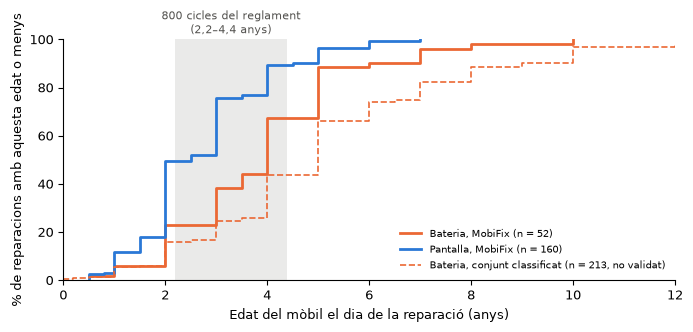

In [5]:
def corba(ax, edats, **kw):
    e = np.sort(edats.to_numpy())
    ax.step(e, np.arange(1, len(e) + 1) / len(e) * 100, where="post", **kw)

fig, ax = plt.subplots(figsize=(7, 3.4))
lo, hi = 800 / 365, 800 / (0.5 * 365)
ax.axvspan(lo, hi, color=GRIS, alpha=0.18, lw=0)
ax.text((lo + hi) / 2, 101, f"800 cicles del reglament\n({lo:.1f}–{hi:.1f} anys)".replace(".", ","),
        ha="center", va="bottom", fontsize=8, color="#52514e")
corba(ax, bat_mf["edat_neta"], color=BATERIA, lw=2, label=f"Bateria, MobiFix (n = {len(bat_mf)})")
corba(ax, pan_mf["edat_neta"], color=PANTALLA, lw=2, label=f"Pantalla, MobiFix (n = {len(pan_mf)})")
corba(ax, bat_tots["edat_neta"], color=BATERIA, lw=1.2, ls="--",
      label=f"Bateria, conjunt classificat (n = {len(bat_tots)}, no validat)")
ax.set_xlim(0, 12); ax.set_ylim(0, 100)
ax.set_xlabel("Edat del mòbil el dia de la reparació (anys)")
ax.set_ylabel("% de reparacions amb aquesta edat o menys")
ax.legend(fontsize=7.5, frameon=False, loc="lower right")
plt.tight_layout()
fig.savefig(comu.POST / "b2_edat_bateria.png", dpi=200, bbox_inches="tight")
plt.show()

## Complement no validat (conjunt classificat)

Més casos i anys posteriors al 2020, però amb el tipus d'avaria posat pel classificador, que no s'ha validat fora de MobiFix.

In [6]:
periodes = {"Tots": bat_tots, "2013–2019": bat_tots[bat_tots["any_event"] <= 2019],
            "2021–2026": bat_tots[bat_tots["any_event"] >= 2021]}
pd.concat({k: mediana_ic(v) for k, v in periodes.items()}, axis=1).T

,n,mediana,ic_inf,ic_sup
Tots,213.0,5.0,4.0,5.0
2013–2019,66.0,4.0,3.5,4.0
2021–2026,145.0,5.0,5.0,6.0


In [7]:
# Edat segons el símptoma descrit, sobre tots els registres amb edat
s = comu.simptomes(tots["problem"])
amb_s = pd.concat([tots, s], axis=1)
pd.concat({nom: mediana_ic(amb_s[amb_s[nom]]) for nom in comu.SIMPTOMES}, axis=1).T

,n,mediana,ic_inf,ic_sup
no_carrega,66.0,4.0,3.0,5.0
dura_poc,23.0,5.0,2.0,6.0
no_sencen,54.0,4.5,3.0,5.0
inflada,11.0,6.5,5.0,8.0
